<a href="https://colab.research.google.com/github/HamzaBanjanovic/fly-by-wire-simulation/blob/main/simulation/sim1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random

a = 4 #the properties of the air causing the angular acceleration to increase, depends on air density, speed squared, wing area, the aircrafts shape, and how hard is it to rotat
b = 1 # how effective the input is, meaning how "strong" the maximum push of the pilots commands are
dt = 0.01
u = 0 # how hard the pilot pulls the stick compared to the maximum he can
theta = 0.01 # nose angle, where the plane is
omega = 0 # angular velocity aka. rotation speed, how fast the plane is turning
alpha = 0 # how hard the plane is being pushed by those forces from a, while they increase as the angle increases amplifying a
times = []
angles = []
u_values = []

'''
new position = old position + speed × little time slice
new speed = old speed + acceleration × little time slice

'''

target = 0 # where we want our nose to be, depending if stable or at a target
I = 0
e_prev = target - theta # initial error, if its
Kp = 10
Ki = 0
Kd = 3

queue = [0]*25 # delay, initial is all zeroes before the list gets filled up



In [ ]:
for i in range(5000):
  # Sensors with a little noise
  s1 = theta + random.gauss(0, 0.005) # Sensor 1
  s2 = theta + random.gauss(0, 0.005) # Sensor 2
  s3 = theta + random.gauss(0, 0.005) # Sensor 3
  sensors = sorted([s1, s2, s3])

  e = target - theta # Negative if going up, signalling that the P part needs to go DOWN when influencing u (Kp*e)
  I = I + e*dt # little errors, adding them up over time
  D = (e - e_prev)/dt  # basically omega, just negative, telling us the direction the plane should to to get counterbalanced
  u = Kp*e + Ki*I + Kd*D # full controller input
  if(u < -1): # Capping the controllers push, the plane cannot physically push more than that
    u = -1
  elif(u > 1):
    u = 1


  e_prev = e


  queue.append(u) # add the current u, it will get its turn in len(queue) turns
  u_used = queue.pop(0) # remove the first element and use it as computer input, meaning its behind len(queue) * 0.01 seconds



  alpha = a * theta + b * u_used # theta times a, acceleration increases ever so slightly
  omega = omega + alpha * dt # speed of rotation infleunced by the push meaning alpha
  theta = theta + omega * dt # current angle influenced by the sum of all previous speeds
  times.append(i * dt) # add the time axis little second by little second
  angles.append(theta) # add how the angle changes over time
  u_values.append(u_used) # add the current stick push

In [ ]:
# Graphing the change of the angle over time using matmatplotlib
import matplotlib.pyplot as plt
plt.plot(times, angles)
plt.xlabel("t [s]")
plt.ylabel("theta [rad]")
plt.title("PD stabilisation delay 250ms")
plt.savefig("figure1.png", dpi=150)
plt.show()

plt.plot(times, u_values)
plt.xlabel("t [s]")
plt.ylabel("u [controller input]")
plt.title("Computer stabilisation input (capped at 1)")
plt.savefig("figure2.png", dpi=150)
plt.show()

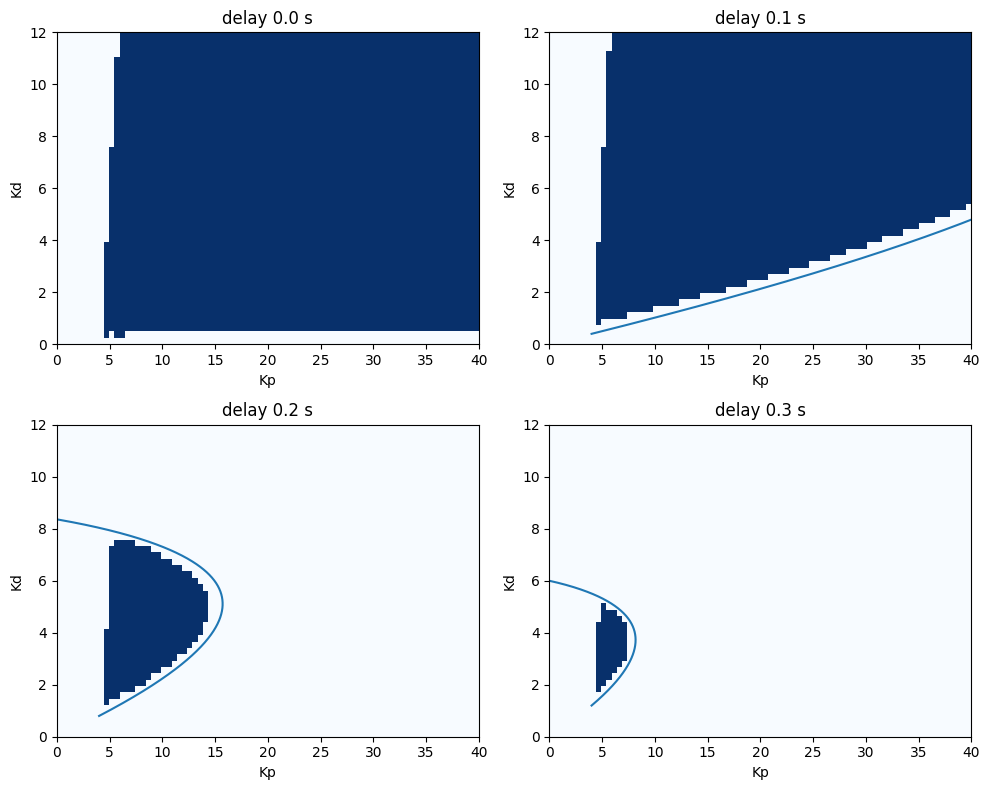

In [13]:
# Creating a settles function that will allow us to iterate over many possible combinations of Kp-Kd combinations in order to create a safe zone map
import matplotlib.pyplot as plt
import math
def settles(Kp, Kd, delay):
  a = 4 #the properties of the air causing the angular acceleration to increase, depends on air density, speed squared, wing area, the aircrafts shape, and how hard is it to rotat
  b = 1 # how effective the input is, meaning how "strong" the maximum push of the pilots commands are
  dt = 0.01
  u = 0 # how hard the pilot pulls the stick compared to the maximum he can
  theta = 0.01 # nose angle, where the plane is
  omega = 0 # angular velocity aka. rotation speed, how fast the plane is turning
  alpha = 0 # how hard the plane is being pushed by those forces from a, while they increase as the angle increases amplifying a



  target = 0 # where we want our nose to be, depending if stable or at a target

  e_prev = target - theta # initial error, if its




  queue = [0]*delay # delay, initial is all zeroes before the list gets filled up

  iterations = 1500
  for i in range(iterations):

    e = target - theta # Negative if going up, signalling that the P part needs to go DOWN when influencing u (Kp*e)
    D = (e - e_prev)/dt  # basically omega, just negative, telling us the direction the plane should to to get counterbalanced
    u = Kp*e + Kd*D # full controller input
    '''
    # We dont need this for now, the point of this is to show the impact of delay on the safe-zone map
    if(u < -1): # Capping the controllers push, the plane cannot physically push more than that
      u = -1
    elif(u > 1):
      u = 1
    '''

    e_prev = e


    queue.append(u) # add the current u, it will get its turn in len(queue) turns
    u_used = queue.pop(0) # remove the first element and use it as computer input, meaning its behind len(queue) * 0.01 seconds



    alpha = a * theta + b * u_used # theta times a, acceleration increases ever so slightly
    omega = omega + alpha * dt # speed of rotation infleunced by the push meaning alpha
    theta = theta + omega * dt # current angle influenced by the sum of all previous speeds
    if(abs(theta) > 1): # If theta is bigger than about 60 degrees its safe to say the plane has toppled
      return False

    if(i >= iterations - 300): # Check if it has stabilised in the last 3 seconds, otherwise discarded as wobbling
      if(abs(theta) > 0.002):
        return False

  return True


Kp_list = [i*0.5 for i in range(81)] # 0.0 to 40.0 by increment 0.5
Kd_list = [i*0.25 for i in range(49)] # 0.0 to 12.0 by increment 0.25

def list_safe_zone_map(settles, kp_values, kd_values, delay): # Function that creates a nested list for each combination of values
  safe_zone_map = []
  for i in range(len(kd_values)):
    safe_zone_map.append([])
    for j in range(len(kp_values)):
      if(settles(kp_values[j], kd_values[i], delay)):
        safe_zone_map[i].append(1)
      else:
        safe_zone_map[i].append(0)
  return safe_zone_map






plt.figure(figsize=(10, 8)) # Sets the size for the whole figure
def graph_safe_zone_map(delay): # Graphs one graph per call
  plt.xlabel("Kp")
  plt.ylabel("Kd")
  plt.title(f"delay {delay/100} s")
  plt.imshow(list_safe_zone_map(settles, Kp_list, Kd_list, delay), origin="lower", extent=[0, 40, 0, 12], aspect="auto", cmap="Blues")

  if delay > 0:
    tau = delay * 0.01
    P = D = 0 # initialise needed variables
    P_values, D_values = [], []
    w = 0.01
    while P >= 0 and D >= 0:
      # Stability boundary (D-subdivision method, Stepan 2009, Phil. Trans. R. Soc. A 367, pp. 1203-1205).
      P = (w*w + 4) * math.cos(w * tau)
      D = (w*w + 4) * math.sin(w * tau) / w
      P_values.append(P)
      D_values.append(D)
      w = w + 0.01

    plt.plot(P_values, D_values) # plot the line
    plt.xlim(0, 40) #boundary for x axis since it automatically zooms out
    plt.ylim(0, 12) #boundary for y axis same reason





# Graph all 4 delays

plt.subplot(2, 2, 1)
graph_safe_zone_map(0)
plt.subplot(2, 2, 2)
graph_safe_zone_map(10)
plt.subplot(2, 2, 3)
graph_safe_zone_map(20)
plt.subplot(2, 2, 4)
graph_safe_zone_map(30)

plt.tight_layout() # Remove the overlap of title and axis



